In [1]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import joblib

# Load the data
df = pd.read_excel("leaderboard.xlsx")

df.head()

,Complexity,time bound,performance,Engagement,Total points,Learner type
0,1,3,42,12.0,60.0,Medium Learner
1,1,3,35,12.0,48.0,Slow Learner
2,1,3,40,13.0,58.0,Medium Learner
3,1,3,45,10.0,61.0,Medium Learner
4,1,3,50,12.0,69.0,Medium Learner


In [2]:
# Preprocess the data
# Select relevant columns for the input (Complexity, Total points)
X = df[['Complexity', 'Total points']]

# One-hot encode the 'learning_level' column
y = pd.get_dummies(df['Learner type'])

# Standardize the input features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


In [3]:
# Build a Sequential model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X_train.shape[1],)),  # Input layer
    tf.keras.layers.Dense(64, activation='relu'),  # First hidden layer
    tf.keras.layers.Dense(32, activation='relu'),  # Second hidden layer
    tf.keras.layers.Dense(y_train.shape[1], activation='softmax')  # Output layer with softmax for multi-class classification
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                192       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 3)                 99        
                                                                 
Total params: 2371 (9.26 KB)
Trainable params: 2371 (9.26 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [4]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test))


Epoch 1/50
10/10 [==============================] - 1s 16ms/step - loss: 1.1106 - accuracy: 0.2366 - val_loss: 0.9911 - val_accuracy: 0.9375
Epoch 2/50
10/10 [==============================] - 0s 4ms/step - loss: 0.9107 - accuracy: 0.9148 - val_loss: 0.8289 - val_accuracy: 0.8375
Epoch 3/50
10/10 [==============================] - 0s 3ms/step - loss: 0.7399 - accuracy: 0.8770 - val_loss: 0.6841 - val_accuracy: 0.8375
Epoch 4/50
10/10 [==============================] - 0s 3ms/step - loss: 0.5981 - accuracy: 0.8770 - val_loss: 0.5578 - val_accuracy: 0.8375
Epoch 5/50
10/10 [==============================] - 0s 4ms/step - loss: 0.4802 - accuracy: 0.8833 - val_loss: 0.4474 - val_accuracy: 0.8375
Epoch 6/50
10/10 [==============================] - 0s 4ms/step - loss: 0.3820 - accuracy: 0.8991 - val_loss: 0.3553 - val_accuracy: 0.8750
Epoch 7/50
10/10 [==============================] - 0s 4ms/step - loss: 0.3117 - accuracy: 0.9117 - val_loss: 0.2852 - val_accuracy: 0.9125
Epoch 8/50
10/10 [=

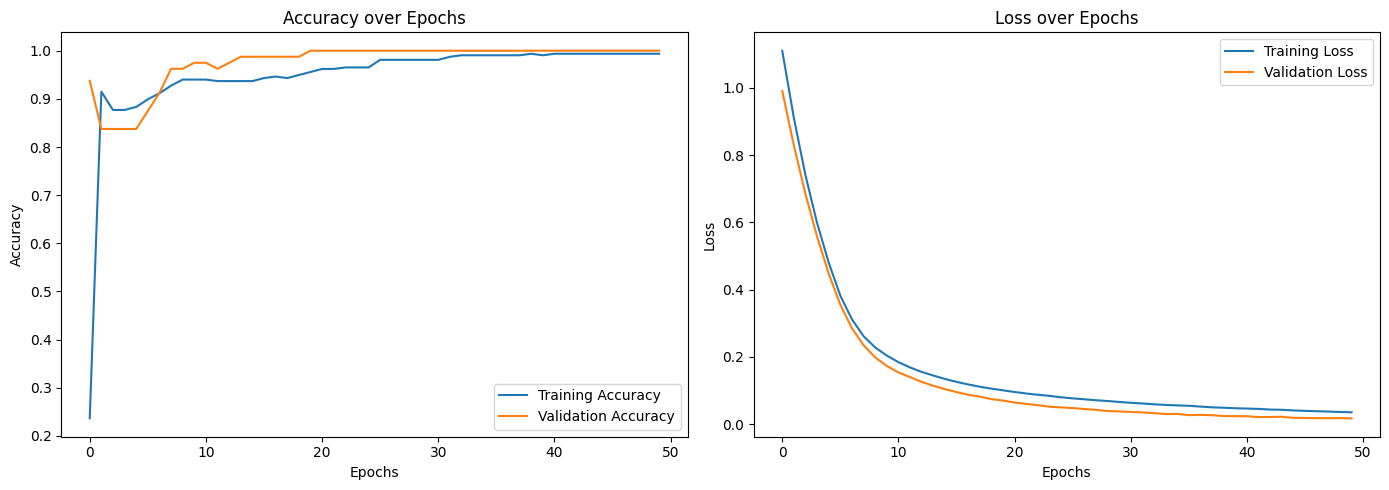

In [5]:
# Plot accuracy and loss over epochs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot training and validation accuracy
ax1.plot(history.history['accuracy'], label='Training Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.set_title('Accuracy over Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()

# Plot training and validation loss
ax2.plot(history.history['loss'], label='Training Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Loss over Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()

# Show the plots
plt.tight_layout()
plt.show()

3/3 [==============================] - 0s 1ms/step


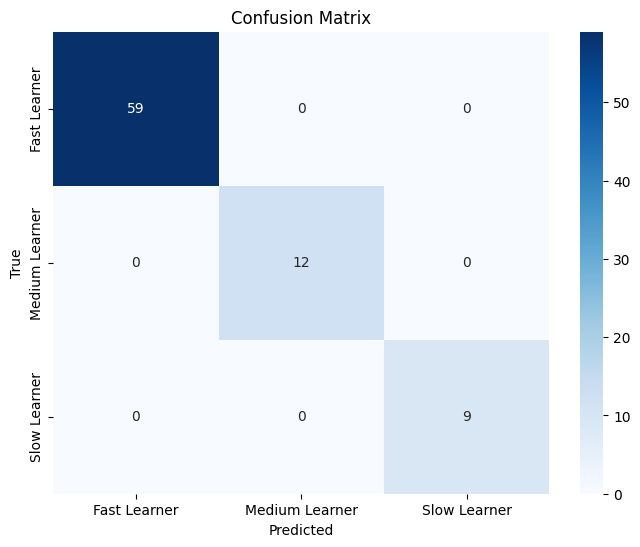

In [6]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predict the labels on the test set
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

# Generate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=y.columns, yticklabels=y.columns)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [7]:
# Save the model after training
model.save('leader_board_model.h5')


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [8]:
joblib.dump(scaler, 'scaler.pkl')  # Save the scaler

['scaler.pkl']